<a href="https://colab.research.google.com/github/asifalimahar1235-cyber/SolarSense-Climate-AI/blob/main/SolarSense_Veritas_AI_Hackathon_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       SOLARSENSE - CLIMATE AI PROJECT

[1/5] Downloading NASA POWER climate data...
NASA data downloaded!
Records: 2557

[2/5] Preparing machine-learning dataset...
Usable observations: 2557
Features: ['solar_today', 'temperature', 'humidity', 'cloud', 'season_sin', 'season_cos']

[3/5] Training AI model...
Model training completed!

[4/5] Evaluating model...

             TEST RESULTS
Linear Regression MAE: 0.4079 kWh/m²/day
Linear Regression RMSE: 0.5947 kWh/m²/day
Linear Regression R²: 0.7872
Baseline MAE: 0.4083 kWh/m²/day
MAE improvement vs baseline: 0.10%
The model improved on the baseline.

[5/5] Generating prediction graph...


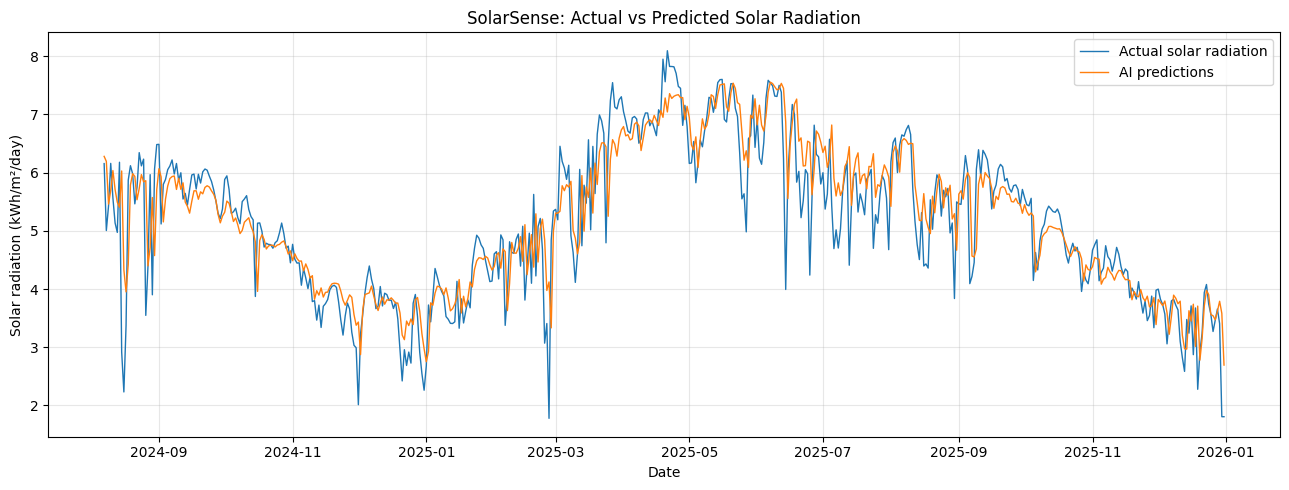


Results saved as solarsense_results.csv
Data source: NASA POWER
Location: Ghotki, Sindh, Pakistan

SOLARSENSE RUN COMPLETED!


In [ ]:

# ============================================================
# SOLARSENSE: AI-BASED NEXT-DAY SOLAR RADIATION FORECASTING
# Location: Ghotki, Sindh, Pakistan
# Dataset: NASA POWER
# ============================================================

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from datetime import datetime

print("=" * 60)
print("       SOLARSENSE - CLIMATE AI PROJECT")
print("=" * 60)

# 1. LOCATION AND DATA SETTINGS
LAT = 28.0167
LON = 69.3167
START = "20190101"
END = "20251231"

# 2. DOWNLOAD NASA POWER DATA
print("\n[1/5] Downloading NASA POWER climate data...")

base_url = "https://power.larc.nasa.gov/api/temporal/daily/point"

parameters = [
    "ALLSKY_SFC_SW_DWN",
    "T2M",
    "RH2M",
    "CLOUD_AMT"
]

params = {
    "parameters": ",".join(parameters),
    "community": "RE",
    "longitude": LON,
    "latitude": LAT,
    "start": START,
    "end": END,
    "format": "JSON"
}

response = requests.get(base_url, params=params, timeout=90)

if response.status_code != 200:
    raise RuntimeError(
        "NASA POWER request failed. Check internet and try again."
    )

result = response.json()
raw = result["properties"]["parameter"]

df = pd.DataFrame(raw)
df.index = pd.to_datetime(df.index, format="%Y%m%d")
df.index.name = "DATE"

df = df.rename(columns={
    "ALLSKY_SFC_SW_DWN": "solar",
    "T2M": "temperature",
    "RH2M": "humidity",
    "CLOUD_AMT": "cloud"
})

# Retry without cloud if NASA does not provide that parameter
if "cloud" not in df.columns:
    print("Cloud data unavailable; retrying without cloud...")
    params["parameters"] = ",".join(parameters[:3])
    response = requests.get(base_url, params=params, timeout=90)
    response.raise_for_status()
    raw = response.json()["properties"]["parameter"]
    df = pd.DataFrame(raw)
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df = df.rename(columns={
        "ALLSKY_SFC_SW_DWN": "solar",
        "T2M": "temperature",
        "RH2M": "humidity"
    })
    df["cloud"] = np.nan

# NASA missing-data sentinel
df = df.replace(-999, np.nan)

print("NASA data downloaded!")
print("Records:", len(df))

# 3. FEATURE ENGINEERING
print("\n[2/5] Preparing machine-learning dataset...")

df["solar_today"] = df["solar"]
df["day_of_year"] = df.index.dayofyear

df["season_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)
df["season_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

# Predict tomorrow's solar radiation
df["target"] = df["solar"].shift(-1)

features = [
    "solar_today",
    "temperature",
    "humidity",
    "cloud",
    "season_sin",
    "season_cos"
]

features = [c for c in features if c in df.columns]

data = df[features + ["target"]].copy()
data = data.interpolate(limit=3).dropna()

if len(data) < 100:
    raise RuntimeError("Not enough valid observations to train.")

X = data[features]
y = data["target"]

print("Usable observations:", len(data))
print("Features:", features)

# 4. CHRONOLOGICAL TRAIN/TEST SPLIT
print("\n[3/5] Training AI model...")

split = int(len(data) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

# Persistence baseline: tomorrow = today's solar radiation
baseline = X_test["solar_today"].values

print("Model training completed!")

# 5. EVALUATION
print("\n[4/5] Evaluating model...")

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

baseline_mae = mean_absolute_error(y_test, baseline)

improvement = (
    (baseline_mae - mae) / baseline_mae * 100
    if baseline_mae != 0 else 0
)

print("\n" + "=" * 45)
print("             TEST RESULTS")
print("=" * 45)

print(f"Linear Regression MAE: {mae:.4f} kWh/m²/day")
print(f"Linear Regression RMSE: {rmse:.4f} kWh/m²/day")
print(f"Linear Regression R²: {r2:.4f}")
print(f"Baseline MAE: {baseline_mae:.4f} kWh/m²/day")
print(f"MAE improvement vs baseline: {improvement:.2f}%")

if improvement > 0:
    print("The model improved on the baseline.")
else:
    print("The model did not outperform the baseline.")

# 6. VISUALIZATION
print("\n[5/5] Generating prediction graph...")

plt.figure(figsize=(13, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual solar radiation",
    linewidth=1
)

plt.plot(
    y_test.index,
    predictions,
    label="AI predictions",
    linewidth=1
)

plt.title("SolarSense: Actual vs Predicted Solar Radiation")
plt.xlabel("Date")
plt.ylabel("Solar radiation (kWh/m²/day)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. SAVE RESULTS
results = pd.DataFrame({
    "date": y_test.index,
    "actual": y_test.values,
    "predicted": predictions,
    "baseline": baseline
})

results.to_csv("solarsense_results.csv", index=False)

print("\nResults saved as solarsense_results.csv")
print("Data source: NASA POWER")
print("Location: Ghotki, Sindh, Pakistan")
print("\nSOLARSENSE RUN COMPLETED!")

In [2]:
from google.colab import files
files.download("solarsense_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>